# Часть 1 Бустинг (5 баллов)

В этой части будем предсказывать зарплату data scientist-ов в зависимости  от ряда факторов с помощью градиентного бустинга.

В датасете есть следующие признаки:



* work_year: The number of years of work experience in the field of data science.

* experience_level: The level of experience, such as Junior, Senior, or Lead.

* employment_type: The type of employment, such as Full-time or Contract.

* job_title: The specific job title or role, such as Data Analyst or Data Scientist.

* salary: The salary amount for the given job.

* salary_currency: The currency in which the salary is denoted.

* salary_in_usd: The equivalent salary amount converted to US dollars (USD) for comparison purposes.

* employee_residence: The country or region where the employee resides.

* remote_ratio: The percentage of remote work offered in the job.

* company_location: The location of the company or organization.

* company_size: The company's size is categorized as Small, Medium, or Large.

In [146]:
import pandas as pd

df = pd.read_csv("ds_salaries.csv")
df.head()

,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,2023,SE,FT,Principal Data Scientist,80000,EUR,85847,ES,100,ES,L
1,2023,MI,CT,ML Engineer,30000,USD,30000,US,100,US,S
2,2023,MI,CT,ML Engineer,25500,USD,25500,US,100,US,S
3,2023,SE,FT,Data Scientist,175000,USD,175000,CA,100,CA,M
4,2023,SE,FT,Data Scientist,120000,USD,120000,CA,100,CA,M


In [147]:
df.shape

(3755, 11)

## Задание 1 (0.5 балла) Подготовка



*   Разделите выборку на train, val, test (80%, 10%, 10%)
*   Выдерите salary_in_usd в качестве таргета
*   Найдите и удалите признак, из-за которого возможен лик в данных


salary, salary_currency вызывают утечку данных. Целевая переменная очень сильно коррелирует с salary, т.к. выводится из нее через конвертацию при помощи столбца salary_currency. Если мы оставим эти 2 признака, то модель научится делать конвертацию валют, а не предсказывать. Поэтому salary, salary_currency необходимо удалить

In [148]:
from sklearn.model_selection import train_test_split

df = df.drop(columns=['salary', 'salary_currency'])
X = df.drop(columns=['salary_in_usd'])
y = df['salary_in_usd']
X_train_0, X_test, y_train_0, y_test = train_test_split(X, y, test_size=0.1, random_state=69)
X_train, X_val, y_train, y_val = train_test_split(X_train_0, y_train_0, test_size=1/9, random_state=69)

In [149]:
X_train_0 = X_train
X_val_0 = X_val
X_test_0 = X_test

## Задание 2 (0.5 балла) Линейная модель


*   Закодируйте категориальные  признаки с помощью OneHotEncoder
*   Обучите модель линейной регрессии
*   Оцените  качество через MAPE и RMSE


In [150]:
df.dtypes

,0
work_year,int64
experience_level,object
employment_type,object
job_title,object
salary_in_usd,int64
employee_residence,object
remote_ratio,int64
company_location,object
company_size,object


In [151]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_percentage_error, mean_squared_error
from sklearn.preprocessing import OneHotEncoder
import numpy as np

cat_features = ['experience_level', 'employment_type', 'job_title', 'employee_residence', 'company_location', 'company_size']
num_features = ['work_year', 'remote_ratio']
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

X_train_cat = encoder.fit_transform(X_train[cat_features])
X_val_cat = encoder.transform(X_val[cat_features])
X_test_cat = encoder.transform(X_test[cat_features])

X_train_num = X_train[num_features]
X_val_num = X_val[num_features]
X_test_num = X_test[num_features]

X_train = pd.concat([pd.DataFrame(X_train_cat).reset_index(drop=True), X_train_num.reset_index(drop=True)], axis=1)

X_val = pd.concat([pd.DataFrame(X_val_cat).reset_index(drop=True), X_val_num.reset_index(drop=True)], axis=1)

X_test = pd.concat([pd.DataFrame(X_test_cat).reset_index(drop=True), X_test_num.reset_index(drop=True)], axis=1)

X_train.columns = X_train.columns.astype(str)
X_val.columns = X_val.columns.astype(str)
X_test.columns = X_test.columns.astype(str)

lr = LinearRegression()
lr.fit(X_train, y_train)

val_pred = lr.predict(X_val)

print('MAPE: ', mean_absolute_percentage_error(y_val, val_pred))
print('RMSE: ', mean_squared_error(y_val, val_pred)**0.5)

MAPE:  0.3321829859300994
RMSE:  46935.52662094195


## Задание 3 (0.5 балла) XGboost

Начнем с библиотеки xgboost.

Обучите модель `XGBRegressor` на тех же данных, что линейную модель, подобрав оптимальные гиперпараметры (`max_depth, learning_rate, n_estimators, gamma`, etc.) по валидационной выборке. Оцените качество итоговой модели (MAPE, RMSE), скорость обучения и скорость предсказания.

In [152]:
from xgboost.sklearn import XGBRegressor

params = {
    'max_depth' : 6,
    'learning_rate' : 0.1,
    'n_estimators' : 400,
    'gamma' : 0.1,
    'random_state' : 42
}

best_rmse = 10000000000000
best_par = params.copy()
for m_d in [4, 5, 6]:
  for l_r in [0.05, 0.1, 0.15]:
    for n_e in [150, 300]:
      for g in [0, 0.1, 0.3]:
        model = XGBRegressor(max_depth=m_d, learning_rate=l_r, n_estimators=n_e, gamma=g, random_state=69)
        model.fit(X_train, y_train)
        val_pred = model.predict(X_val)
        rmse = mean_squared_error(y_val, val_pred) ** 0.5
        if rmse < best_rmse:
          best_rmse = rmse
          best_params = {'max_depth': m_d, 'learning_rate': l_r, 'n_estimators': n_e, 'gamma': g, 'random_state': 69}
xgb = XGBRegressor(max_depth=best_params['max_depth'], learning_rate=best_params['learning_rate'], n_estimators=best_params['n_estimators'], gamma=best_params['gamma'], random_state=69)

In [153]:
xgb.fit(X_train, y_train)
test_pred = xgb.predict(X_test)

print('MAPE: ', mean_absolute_percentage_error(y_test, test_pred))
print('RMSE: ', mean_squared_error(y_test, test_pred)**0.5)

MAPE:  0.37478122115135193
RMSE:  46111.21442772897


In [154]:
import time

start = time.time()
xgb.fit(X_train, y_train)
train_t = time.time() - start

start = time.time()
test_pred = xgb.predict(X_test)
pred_t = time.time() - start
print('Train time:', train_t)
print('Pred time:', pred_t)

Train time: 0.7028012275695801
Pred time: 0.01510167121887207


## Задание 4 (1 балл) CatBoost

Теперь библиотека CatBoost.

Обучите модель `CatBoostRegressor`, подобрав оптимальные гиперпараметры (`depth, learning_rate, iterations`, etc.) по валидационной выборке. Оцените качество итоговой модели (MAPE, RMSE), скорость обучения и скорость предсказания.

In [155]:
!pip install catboost -q

In [156]:
from catboost import CatBoostRegressor

params = {
    'depth' : 8,
    'learning_rate' : 0.1,
    'iterations' : 500,
    'random_seed' : 69
}

best_rmse = 10000000000000
best_par = params.copy()
for d in [5, 7, 9]:
  for l_r in [0.02, 0.1, 0.2]:
    for i in [350, 500, 750]:
      model = CatBoostRegressor(depth=d, learning_rate=l_r, iterations=i, random_seed=69)
      model.fit(X_train, y_train)
      val_pred = model.predict(X_val)
      rmse = mean_squared_error(y_val, val_pred) ** 0.5
      if rmse < best_rmse:
        best_rmse = rmse
        best_params = {'depth': d, 'learning_rate': l_r, 'iterations': i, 'random_seed': 69}
cat = CatBoostRegressor(depth=best_params['depth'], learning_rate=best_params['learning_rate'], iterations=best_params['iterations'], random_seed=69)

Выходные данные были обрезаны до нескольких последних строк (5000).
550:	learn: 40907.7603082	total: 1.22s	remaining: 442ms
551:	learn: 40900.9657697	total: 1.23s	remaining: 440ms
552:	learn: 40899.5430341	total: 1.23s	remaining: 438ms
553:	learn: 40896.8133927	total: 1.23s	remaining: 435ms
554:	learn: 40896.0543559	total: 1.23s	remaining: 433ms
555:	learn: 40895.9162677	total: 1.24s	remaining: 431ms
556:	learn: 40895.2428373	total: 1.24s	remaining: 429ms
557:	learn: 40895.1525276	total: 1.24s	remaining: 426ms
558:	learn: 40894.2803434	total: 1.24s	remaining: 424ms
559:	learn: 40891.4534912	total: 1.24s	remaining: 422ms
560:	learn: 40889.5042906	total: 1.25s	remaining: 420ms
561:	learn: 40889.3020406	total: 1.25s	remaining: 417ms
562:	learn: 40889.0419468	total: 1.25s	remaining: 415ms
563:	learn: 40889.0066175	total: 1.25s	remaining: 413ms
564:	learn: 40880.8562994	total: 1.25s	remaining: 411ms
565:	learn: 40880.5262485	total: 1.26s	remaining: 408ms
566:	learn: 40880.0409590	total: 1.2

In [157]:
start = time.time()
cat.fit(X_train, y_train)
train_t = time.time() - start

start = time.time()
test_pred = cat.predict(X_test)
pred_t = time.time() - start

print('Train time:', train_t)
print('Pred time:', pred_t)
print('MAPE: ', mean_absolute_percentage_error(y_test, test_pred))
print('RMSE: ', mean_squared_error(y_test, test_pred)**0.5)

0:	learn: 62725.5902122	total: 1.94ms	remaining: 1.46s
1:	learn: 62316.0629263	total: 7.22ms	remaining: 2.7s
2:	learn: 61928.5081825	total: 12.4ms	remaining: 3.1s
3:	learn: 61524.5204044	total: 15.7ms	remaining: 2.92s
4:	learn: 61137.6065060	total: 20.8ms	remaining: 3.09s
5:	learn: 60767.3200157	total: 25.9ms	remaining: 3.21s
6:	learn: 60403.0423567	total: 30.9ms	remaining: 3.28s
7:	learn: 60045.8832839	total: 33.2ms	remaining: 3.08s
8:	learn: 59716.1055676	total: 36.5ms	remaining: 3.01s
9:	learn: 59384.9778702	total: 42.1ms	remaining: 3.12s
10:	learn: 59084.4524749	total: 45.5ms	remaining: 3.05s
11:	learn: 58773.4905573	total: 50.6ms	remaining: 3.11s
12:	learn: 58468.9454371	total: 55.8ms	remaining: 3.16s
13:	learn: 58186.7462783	total: 61.2ms	remaining: 3.21s
14:	learn: 57894.9560376	total: 67.4ms	remaining: 3.3s
15:	learn: 57638.1024333	total: 73.6ms	remaining: 3.38s
16:	learn: 57377.9117702	total: 78.9ms	remaining: 3.4s
17:	learn: 57150.2645699	total: 84ms	remaining: 3.41s
18:	lear

Для применения catboost моделей не обязательно сначала кодировать категориальные признаки, модель может кодировать их сама. Обучите catboost с подбором оптимальных гиперпараметров снова, используя pool для передачи данных в модель с указанием какие признаки категориальные, а какие нет с помощью параметра cat_features. Оцените качество и время. Стало ли лучше?

In [160]:
from catboost import Pool

train_pool = Pool(X_train_0, y_train, cat_features=cat_features)
val_pool = Pool(X_val_0, y_val, cat_features=cat_features)
test_pool = Pool(X_test_0, y_test, cat_features=cat_features)
best_rmse = 10000000000000
best_par = {}
for d in [5, 7, 9]:
  for l_r in [0.02, 0.1, 0.2]:
    for i in [350, 500, 750]:
      model = CatBoostRegressor(depth=d, learning_rate=l_r, iterations=i, random_seed=69)
      model.fit(train_pool)
      val_pred = model.predict(val_pool)
      rmse = mean_squared_error(y_val, val_pred) ** 0.5
      if rmse < best_rmse:
        best_rmse = rmse
        best_params = {'depth': d, 'learning_rate': l_r, 'iterations': i, 'random_seed': 69}
cat = CatBoostRegressor(depth=best_params['depth'], learning_rate=best_params['learning_rate'], iterations=best_params['iterations'], random_seed=69)

Выходные данные были обрезаны до нескольких последних строк (5000).
550:	learn: 36210.4056263	total: 4.67s	remaining: 1.69s
551:	learn: 36198.2735980	total: 4.68s	remaining: 1.68s
552:	learn: 36189.0834292	total: 4.68s	remaining: 1.67s
553:	learn: 36179.4859009	total: 4.69s	remaining: 1.66s
554:	learn: 36174.8553946	total: 4.7s	remaining: 1.65s
555:	learn: 36164.4602861	total: 4.71s	remaining: 1.64s
556:	learn: 36136.2895137	total: 4.72s	remaining: 1.64s
557:	learn: 36120.8936954	total: 4.73s	remaining: 1.63s
558:	learn: 36119.9652530	total: 4.74s	remaining: 1.62s
559:	learn: 36098.1294980	total: 4.75s	remaining: 1.61s
560:	learn: 36080.4060142	total: 4.76s	remaining: 1.6s
561:	learn: 36075.3691247	total: 4.76s	remaining: 1.59s
562:	learn: 36071.7117073	total: 4.78s	remaining: 1.59s
563:	learn: 36060.8029221	total: 4.8s	remaining: 1.58s
564:	learn: 36054.1245951	total: 4.82s	remaining: 1.58s
565:	learn: 36039.5145001	total: 4.83s	remaining: 1.57s
566:	learn: 36031.2678122	total: 4.83s	

In [161]:
start = time.time()
cat.fit(train_pool)
train_t = time.time() - start

start = time.time()
test_pred = cat.predict(test_pool)
pred_t = time.time() - start

print('Train time:', train_t)
print('Pred time:', pred_t)
print('MAPE: ', mean_absolute_percentage_error(y_test, test_pred))
print('RMSE: ', mean_squared_error(y_test, test_pred)**0.5)

0:	learn: 62784.6627300	total: 9.32ms	remaining: 3.25s
1:	learn: 62487.2519257	total: 18.4ms	remaining: 3.21s
2:	learn: 62153.6109298	total: 26ms	remaining: 3.01s
3:	learn: 61817.8788510	total: 33.1ms	remaining: 2.86s
4:	learn: 61504.4186312	total: 41.3ms	remaining: 2.85s
5:	learn: 61192.1251010	total: 48.8ms	remaining: 2.79s
6:	learn: 60885.4166060	total: 55.8ms	remaining: 2.73s
7:	learn: 60574.0667048	total: 62.8ms	remaining: 2.68s
8:	learn: 60347.8131029	total: 64.9ms	remaining: 2.46s
9:	learn: 60051.1956846	total: 73.5ms	remaining: 2.5s
10:	learn: 59768.8932761	total: 80.3ms	remaining: 2.47s
11:	learn: 59477.8832999	total: 86.5ms	remaining: 2.44s
12:	learn: 59183.1900434	total: 93.6ms	remaining: 2.43s
13:	learn: 58899.0795079	total: 102ms	remaining: 2.45s
14:	learn: 58641.0943261	total: 110ms	remaining: 2.45s
15:	learn: 58381.1254524	total: 117ms	remaining: 2.44s
16:	learn: 58098.3546030	total: 123ms	remaining: 2.42s
17:	learn: 57852.7571198	total: 127ms	remaining: 2.34s
18:	learn:

Без Pool:  
Train time: 3.8941409587860107  
Pred time: 0.007292985916137695  
MAPE:  0.4090670155332538  
RMSE:  45899.10488027622   

**Ответ:** Результаты практически идентичны, оба способа корректно обрабатывают категориальные признаки. Pool удобнее при работе с большими данными, т.к. позволяет обучить модель без предварительного кодирования категориальных признаков. Использование Pool не привело к улучшению качества модели, но позволило ускорить обучение и предсказание, а также упростило подготовку данных. На данных зарплат разница незначительна, скорее всего, это связано с тем, что датасет небольшой и категорий не очень много.



## Задание 5 (0.5 балла) LightGBM

И наконец библиотека LightGBM - используйте `LGBMRegressor`, снова подберите гиперпараметры, оцените качество и скорость.


In [162]:
from lightgbm import LGBMRegressor


params = {
    'max_depth' : 4,
    'learning_rate' : 0.05,
    'n_estimators' : 200,
    'random_state' : 69
}

best_rmse = 10000000000000
best_par = params.copy()
for m_d in [4, 6, 9]:
  for l_r in [0.05, 0.1, 0.15]:
    for n_e in [150, 300, 500]:
        model = LGBMRegressor(max_depth=m_d, learning_rate=l_r, n_estimators=n_e, random_state=69)
        model.fit(X_train, y_train)
        val_pred = model.predict(X_val)
        rmse = mean_squared_error(y_val, val_pred) ** 0.5
        if rmse < best_rmse:
          best_rmse = rmse
          best_params = {'max_depth': m_d, 'learning_rate': l_r, 'n_estimators': n_e, 'random_state': 69}
lgbm = LGBMRegressor(max_depth=best_params['max_depth'], learning_rate=best_params['learning_rate'], n_estimators=best_params['n_estimators'], random_state=69)

Выходные данные были обрезаны до нескольких последних строк (5000).
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further 

In [163]:
start = time.time()
lgbm.fit(X_train, y_train)
train_t = time.time() - start

start = time.time()
test_pred = lgbm.predict(X_test)
pred_t = time.time() - start
print('Train time:', train_t)
print('Pred time:', pred_t)

print('MAPE: ', mean_absolute_percentage_error(y_test, test_pred))
print('RMSE: ', mean_squared_error(y_test, test_pred)**0.5)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000675 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 80
[LightGBM] [Info] Number of data points in the train set: 3003, number of used features: 38
[LightGBM] [Info] Start training from score 137653.007326
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gai

## Задание 6 (2 балла) Сравнение и выводы

Сравните модели бустинга и сделайте про них выводы, какая из моделей показала лучший/худший результат по качеству, скорости обучения и скорости предсказания? Как отличаются гиперпараметры для разных моделей?

**Ответ:**    
**Линейная модель:**    
MAPE:  0.3321829859300994   
RMSE:  46935.52662094195   
**XGBoost:**  
MAPE:  0.37478122115135193   
RMSE:  46111.21442772897   
Train time: 0.7028012275695801   
Pred time: 0.01510167121887207   
**CatBoost**   
Train time: 3.8941409587860107   
Pred time: 0.007292985916137695   
MAPE:  0.4090670155332538   
RMSE:  45899.10488027622   
**LightGBM**   
Train time: 0.062713623046875   
Pred time: 0.0061931610107421875   
MAPE:  0.4089676325349016   
RMSE:  46491.67446897879   

Сравнивая по RMSE, видно, что лучший результат у CatBoost, худший у Линейной регрессии. Но Линейная регрессия показала наименьшее значение MAPE, из этого можно сделать вывод, что для этого датасета сложные моджели не дали существенного выигрыша по всем метрикам сразу.   
По скорости обучения самым быстром является LightGBM, он значительно превосходит другие метрики.   
По скорости предсказания лучший результат тоже у LightGBM.    
Гиперпараметры у XGBoost и LightBoost одинаковые: глубина дерева, скорость обучения и количество деревьев. В CatBoost параметры имеют такой же смысл, но построени деревьев у этих моделей различаются, поэтому одинаковые параметры приводят к разным результатам.
CatBoost имеет лучшие метрики качества модели, LightGBM - самый быстрый, XGBoost занимает промежуточное значение

# Часть 2 Кластеризация (5 баллов)

Будем работать с данными о том, каких исполнителей слушают пользователи музыкального сервиса.

Каждая строка таблицы - информация об одном пользователе. Каждый столбец - это исполнитель (The Beatles, Radiohead, etc.)

Для каждой пары (пользователь, исполнитель) в таблице стоит число - доля прослушивания этого исполнителя этим пользователем.


In [241]:
import pandas as pd
ratings = pd.read_excel("https://github.com/evgpat/edu_stepik_rec_sys/blob/main/datasets/sample_matrix.xlsx?raw=true", engine='openpyxl')
ratings.head()

,user,the beatles,radiohead,deathcab for cutie,coldplay,modest mouse,sufjan stevens,dylan. bob,red hot clili peppers,pink fluid,...,municipal waste,townes van zandt,curtis mayfield,jewel,lamb,michal w. smith,群星,agalloch,meshuggah,yellowcard
0,0,NaN,0.020417,NaN,NaN,NaN,NaN,NaN,0.030496,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,NaN,0.184962,0.024561,NaN,NaN,0.136341,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,NaN,NaN,0.028635,NaN,NaN,NaN,0.024559,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4,0.043529,0.086281,0.034590,0.016712,0.015935,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Будем строить кластеризацию исполнителей: если двух исполнителей слушало много людей примерно одинаковую долю своего времени (то есть векторы близки в пространстве), то, возможно исполнители похожи. Эта информация может быть полезна при построении рекомендательных систем.

## Задание 1 (0.5 балла) Подготовка

Транспонируем матрицу ratings, чтобы по строкам стояли исполнители.

In [242]:
ratings = ratings.T

Выкиньте строку под названием `user`.

In [243]:
ratings = ratings = ratings.drop(index='user')

В таблице много пропусков, так как пользователи слушают не всех-всех исполнителей, чья музыка представлена в сервисе, а некоторое подмножество (обычно около 30 исполнителей)


Доля исполнителя в музыке, прослушанной  пользователем, равна 0, если пользователь никогда не слушал музыку данного музыканта, поэтому заполните пропуски нулями.



In [244]:
ratings = ratings.fillna(0)
ratings.sample()

,0,1,2,3,4,5,6,7,8,9,...,4990,4991,4992,4993,4994,4995,4996,4997,4998,4999
every time i die,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [245]:
ratings.isnull().sum().sum()

np.int64(0)

## Задание 2 (0.5 балла) Первая кластеризация

Примените KMeans с 5ю кластерами, сохраните полученные лейблы

In [246]:
from sklearn.cluster import KMeans

km = KMeans(n_clusters=5, random_state=42)
labels = km.fit_predict(ratings)
ratings['cluster'] = labels

Выведите размеры кластеров. Полезной ли получилась кластеризация? Почему KMeans может выдать такой результат?

In [247]:
ratings['cluster'].value_counts()

,count
cluster,
3,882
0,115
4,1
2,1
1,1


**Ответ:** Кластеры - неравномерные? 'nj ,tcgjktpyfz rkfcnthbpfwbz. Это проблема из-за выбросов. Некоторые исполнители прослушиваются гораздо чаще большинства. KMeans, минимизирует внутрикластерные расстояния, отправляя таких исполнителей в отдельные кластеры

## Задание 3 (0.5 балла) Объяснение результатов

При кластеризации получилось $\geq 1$ кластера размера 1. Выведите исполнителей, которые составляют такие кластеры. Среди них должна быть группа The Beatles.

In [248]:
size = ratings['cluster'].value_counts()
for i in size[size == 1].index:
  print(ratings[ratings['cluster'] == i].index[0])

the beatles
niИ
日dir en grey


Изучите данные, почему именно The Beatles выделяется?

Подсказка: посмотрите на долю пользователей, которые слушают каждого исполнителя, среднюю долю прослушивания.

In [ ]:
artists = ratings.drop('cluster', axis=1)

share_users = (artists > 0).mean(axis=1)
mean_share = artists.replace(0, np.nan).mean(axis=1)

stats = pd.DataFrame({
    'share_users': share_users,
    'mean_share': mean_share
})

stats = stats.sort_values('share_users', ascending=False)

stats.head(10)

In [256]:
df = ratings.drop(columns=['cluster'])
l_share = (df > 0).mean(axis=1)
mean_share = df.replace(0, np.nan).mean(axis=1)
share = pd.DataFrame({'l_share': l_share, 'mean_share': mean_share})
share = share.sort_values('l_share')
share.tail(15)

,l_share,mean_share
beck,0.1138,0.030988
elliotte smith,0.1166,0.041528
led zeppelin.,0.1180,0.031758
the shins,0.1182,0.025142
niИ,0.1182,0.054740
kanye west,0.1250,0.037128
pink fluid,0.1256,0.039085
red hot clili peppers,0.1258,0.031752
dylan. bob,0.1262,0.039323
sufjan stevens,0.1292,0.038460


**Ответ:** The Beatles слушало несравнимо больше пользователей, чем любого другого исполнителя, их вектор в пространстве признаков ненулевой по многим измерениям. Средняя доля прослушивания тоже высокая. Поэтому результат вектора находится очень далеко от всех остальных исполнителей. KMeans не может объединить их без огромных потерь качества кластеризации, из-за этого выделяет отдельный кластер

## Задание 4 (0.5 балла) Улучшение кластеризации

Попытаемся избавиться от этой проблемы: нормализуйте данные при помощи `normalize`.

In [257]:
from sklearn.preprocessing import normalize

df_norm = normalize(df, norm='l2')
df_norm = pd.DataFrame(df_norm, index=df.index, columns=df.columns)
df_norm

,0,1,2,3,4,5,6,7,8,9,...,4990,4991,4992,4993,4994,4995,4996,4997,4998,4999
the beatles,0.000000,0.000000,0.000000,0.0,0.012054,0.000000,0.0,0.0,0.025864,0.004880,...,0.000000,0.0,0.033554,0.010569,0.002199,0.004952,0.0,0.021302,0.0,0.000000
radiohead,0.009348,0.084688,0.000000,0.0,0.039505,0.002894,0.0,0.0,0.000000,0.008771,...,0.008120,0.0,0.000000,0.000000,0.005122,0.000000,0.0,0.000000,0.0,0.000000
deathcab for cutie,0.000000,0.017278,0.020144,0.0,0.024333,0.000000,0.0,0.0,0.000000,0.009391,...,0.085361,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.019622
coldplay,0.000000,0.000000,0.000000,0.0,0.011129,0.000000,0.0,0.0,0.000000,0.000000,...,0.144628,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.000000
modest mouse,0.000000,0.000000,0.000000,0.0,0.010260,0.000000,0.0,0.0,0.000000,0.019597,...,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
michal w. smith,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.000000,0.000000,...,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.000000
群星,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.000000,0.000000,...,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.000000
agalloch,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.000000,0.000000,...,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.000000
meshuggah,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.000000,0.000000,...,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.000000


Примените KMeans с 5ю кластерами на преобразованной матрице, посмотрите на их размеры. Стало ли лучше? Может ли кластеризация быть полезной теперь?

In [258]:
km = km.fit(df_norm)
labels_norm = km.predict(df_norm)
size_norm = pd.Series(labels_norm).value_counts().sort_index()
size_norm

,count
0,79
1,162
2,133
3,140
4,486


**Ответ** После нормализации кластеры стали гораздо более равномерными. После нормализации стало важно не сколько всего слушают исполнителя, а кто его слушает. Кластеризация стало более содержательной, теперь кластеры отражают схожесть аудитории

## Задание 5 (1 балл) Центроиды

Выведите для каждого кластера названия топ-10 исполнителей, ближайших к центроиду по косинусной мере. Проинтерпретируйте результат. Что можно сказать о смысле кластеров?

In [260]:
from scipy.spatial.distance import cosine


centroids = km.cluster_centers_

for i in range(5):
  mask = (labels_norm == i)
  art = df_norm[mask]
  cos_dist = []
  for j in art.values:
    cos_dist.append(cosine(j, centroids[i]))
  cos_dist = pd.Series(cos_dist, index=art.index)
  art_10 = cos_dist.sort_values().head(10)
  art_10 = list(art_10.index)
  print('Кластер', i, art_10)

Кластер 0 ['nas', 'jay-z', 'kanye west', 'lupe the gorilla', 'a tribe called quest', "the roots featuring d'angelo", 'gangstarr', 'little brother', "lil' wayne", 'murs and 9th wonder']
Кластер 1 ['fall out boy', 'the all-americian rejects', 'paramore', 'kelly clarkson', 'john mayer', 'the fray', 'maroon5', 'dashboard confesssional', 'somethings corporate', 'coldplay']
Кластер 2 ['brand new', 'blink-182', 'alkaline trio', 'against me!', 'underoath', 'descendents', 'new found glory', 'less than jake', 'thrice', 'chiodos']
Кластер 3 ['the beatles', 'the rolling stones', 'dylan. bob', 'who', 'led zeppelin.', 'miles davis.', 'simon and garfunkel', 'young, neil', 'pink fluid', 'velvet underground']
Кластер 4 ['radiohead', 'the arcade fire', 'the shins', 'sufjan stevens', 'belle and sebastian', 'broken social scene', 'the pixies', 'animal collective', 'modest mouse', 'spoon']


**Ответ:** Исполнители в одном кластере принадлежат к схожему жанру, имеют пересекающуяся аудиторию

## Задание 6 (1 балл) Визуализация

Хотелось бы как-то визуализировать полученную кластеризацию. Постройте точечные графики `plt.scatter` для нескольких пар признаков исполнителей, покрасив точки в цвета кластеров. Почему визуализации получились такими? Хорошо ли они отражают разделение на кластеры? Почему?

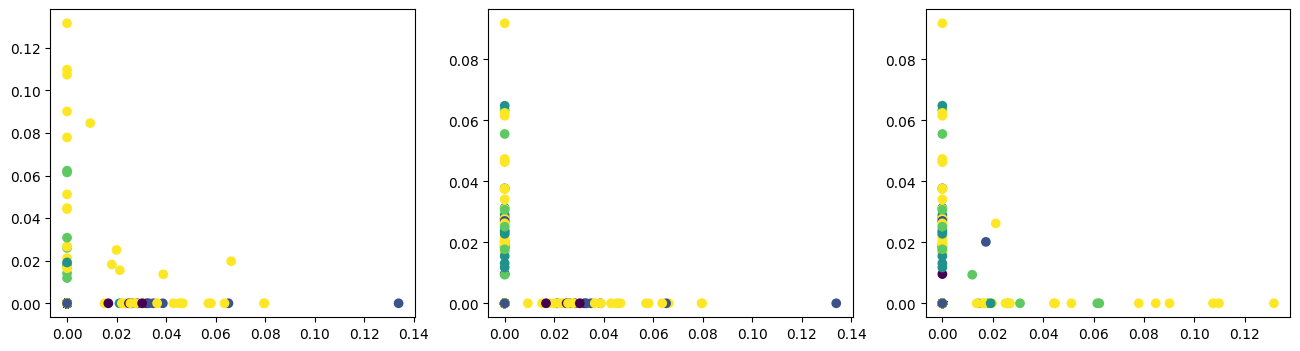

In [267]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
cols = df.columns
axes[0].scatter(df_norm[cols[0]], df_norm[cols[1]], c=labels_norm)
axes[1].scatter(df_norm[cols[0]], df_norm[cols[2]], c=labels_norm)
axes[2].scatter(df_norm[cols[1]], df_norm[cols[2]], c=labels_norm)

**Ответ:** По парам признаков получилось плохо, точки перемешаны хаотично, разделение на кластеры не видно. Это из-за того, что у данных большая размерность, у нас тысячи пользователей, то есть тысячи измерений. При проекции на 2 измерения теряется огромная часть информации о структуре данных. Разделение KMeans в полном пространстве не возможно увидеть в двухмерие



Для визуализации данных высокой размерности существует метод t-SNE (стохастическое вложение соседей с t-распределением). Данный метод является нелинейным методом снижения размерности: каждый объект высокой размерности будет моделироваться объектов более низкой (например, 2) размерности таким образом, чтобы похожие объекты моделировались близкими, непохожие - далекими с большой вероятностью.

Примените `TSNE` из библиотеки `sklearn` и визуализируйте полученные объекты, покрасив их в цвета их кластеров

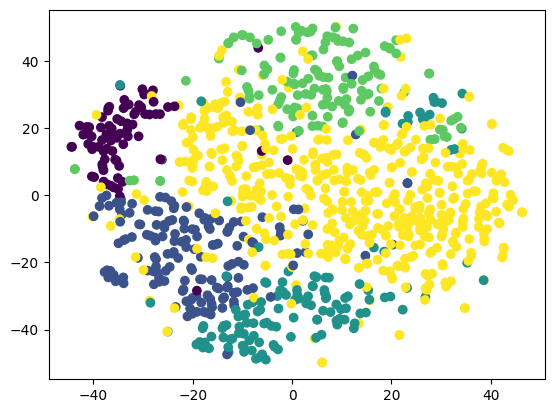

In [268]:
from sklearn.manifold import TSNE

tsne = TSNE(random_state=42)
df_tsne = tsne.fit_transform(df_norm)
plt.figure()
plt.scatter(df_tsne[:, 0], df_tsne[:, 1], c=labels_norm)

## Задание 7 (1 балл) Подбор гиперпараметров

Подберите оптимальное количество кластеров (максимум 100 кластеров) с использованием индекса Силуэта. Зафиксируйте `random_state=42`

In [ ]:
from sklearn.metrics import silhouette_score

# -- YOUR CODE HERE --

Выведите исполнителей, ближайших с центроидам (аналогично заданию 5). Как соотносятся результаты? Остался ли смысл кластеров прежним? Расскажите про смысл 1-2 интересных кластеров, если он изменился и кластеров слишком много, чтобы рассказать про все.

In [ ]:
# -- YOUR CODE HERE --

**Ответ:** # -- YOUR ANSWER HERE --

Сделайте t-SNE визуализацию полученной кластеризации.

In [ ]:
# -- YOUR CODE HERE --

Если кластеров получилось слишком много и визуально цвета плохо отличаются, покрасьте только какой-нибудь интересный кластер из задания выше (`c = (labels == i)`). Хорошо ли этот кластер отражается в визуализации?

In [ ]:
# -- YOUR CODE HERE --

**Ответ:** # -- YOUR ANSWER HERE --